# Miniproyecto 3

En este Jupyter Notebook pueden implementar los códigos necesarios para resolver el **Miniproyecto 3**.

**Importante:** Recuerden que, como grupo, deben **adjuntar el código** en su entrega. En caso de que desarrollen parte del trabajo en este notebook pero **no lo incluyan en la entrega**, **toda la sección de calificación correspondiente al código será evaluada con cero**.

Tengan en cuenta que Coursera utiliza recursos compartidos entre todos los grupos, por lo tanto, si hay muchos equipos trabajando al mismo tiempo, los procesos pueden demorar más de lo previsto.

Pueden agregar todas las celdas de código que consideren necesarias para resolver el miniproyecto. **No hay un límite en este aspecto.**

Grupo 49

Integrantes:
- Juan Sebastian Hernandez
- Juan Carlos Echeverri
- Juan Fernando Contreras

# 1. Importar y revisar los datos

Clasificaremos cada artículo en una de las cinco categorías del CSV. Primero revisamos las columnas, la distribución de categorías y los textos repetidos.

In [2]:
# Configuración para descargar modelos públicos sin enviar tokens guardados
import os
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"

# Importamos las librerías necesarias
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import transformers as ppb

# Semillas para que los resultados sean reproducibles
np.random.seed(42)
torch.manual_seed(42)

# Seleccionamos GPU si está disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo utilizado: {device}")

Dispositivo utilizado: cuda


Ya que estamos trabajando en un repositorio de GitHub, el siguiente código permite descargar el archivo CSV directamente desde el repositorio. Si se quiere trabajar con un archivo local, se tednrá que cambiar la ruta del archivo, ya que este código puede no funcionar correctamente.

In [4]:
# Buscamos el CSV desde microproyecto3/ o desde la raíz del repositorio
DATA_PATH = Path("datos/bbc_text_cls.csv")
if not DATA_PATH.is_file():
    DATA_PATH = Path("microproyecto3") / DATA_PATH

# Si no está en local, lo cargamos desde GitHub, por ejemplo en Colab
if not DATA_PATH.is_file():
    DATA_PATH = (
        "https://raw.githubusercontent.com/JCE2024/"
        "MRI-Classification-Using-Convolutional-Neural-Networks-for-Different-Types-of-Cancer/"
        "main/microproyecto3/datos/bbc_text_cls.csv"
    )

noticias = pd.read_csv(DATA_PATH)

# Revisamos las columnas y las primeras noticias
noticias.info()
display(noticias.head(3))

# Número de artículos de cada categoría
display(noticias["labels"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    2225 non-null   object
 1   labels  2225 non-null   object
dtypes: object(2)
memory usage: 34.9+ KB


,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business


,count
labels,
sport,511
business,510
politics,417
tech,401
entertainment,386


## 1.1. Textos vacíos y duplicados

Contamos los textos ausentes o vacíos y las repeticiones exactas. También comprobamos si un mismo texto tiene etiquetas distintas. Esta revisión nos permitirá decidir cómo preparar los datos antes de dividirlos en entrenamiento, validación y prueba.

In [5]:
n_vacios = noticias["text"].fillna("").str.strip().eq("").sum()
n_duplicados = noticias.duplicated(subset="text").sum()
etiquetas_por_texto = noticias.groupby("text")["labels"].nunique()
n_conflictos = etiquetas_por_texto.gt(1).sum()

print(f"Artículos originales: {len(noticias):,}")
print(f"Categorías: {noticias['labels'].nunique()}")
print(f"Textos ausentes o vacíos: {n_vacios}")
print(f"Repeticiones exactas adicionales: {n_duplicados}")
print(f"Textos con etiquetas contradictorias: {n_conflictos}")

Artículos originales: 2,225
Categorías: 5
Textos ausentes o vacíos: 0
Repeticiones exactas adicionales: 98
Textos con etiquetas contradictorias: 0


Vemos que hay 98 repeticiones exactas adicionales, las eliminaremos antes de dividir los datos para evitar contaminación entre validación y prueba.

In [6]:
# Conservamos una copia de cada texto
noticias_limpias = noticias.drop_duplicates(
    subset="text"
).reset_index(drop=True)

# Revisamos cuántos artículos quedan y su distribución
print(f"Artículos sin duplicados: {len(noticias_limpias):,}")
display(noticias_limpias["labels"].value_counts())

Artículos sin duplicados: 2,127


,count
labels,
sport,505
business,503
politics,403
entertainment,369
tech,347


# 2. Preparación de los datos

Dividimos los artículos sin duplicados en entrenamiento, validación y prueba, con proporciones aproximadas de 70 %, 15 % y 15 %. Conservamos la proporción de las categorías en cada conjunto y usamos la semilla 42 para repetir la división.

In [7]:
# Separamos el 70 % para entrenamiento y reservamos el 30 % restante
noticias_train, noticias_restantes = train_test_split(
    noticias_limpias,
    test_size=0.30,
    random_state=42,
    stratify=noticias_limpias["labels"]
)

# Dividimos lo reservado entre validación y prueba
noticias_val, noticias_test = train_test_split(
    noticias_restantes,
    test_size=0.50,
    random_state=42,
    stratify=noticias_restantes["labels"]
)

print(f"Artículos de entrenamiento: {len(noticias_train)}")
print(f"Artículos de validación: {len(noticias_val)}")
print(f"Artículos de prueba: {len(noticias_test)}")

Artículos de entrenamiento: 1488
Artículos de validación: 319
Artículos de prueba: 320


## 2.1. Conversión de las categorías a números

Las categorías del CSV están escritas como texto. Las asociamos con números del 0 al 4 y aplicamos la misma correspondencia a los tres conjuntos. Conservamos también la correspondencia inversa para interpretar las predicciones.

In [8]:
# Asociamos cada categoría con un identificador numérico
label2id = {
    "business": 0,
    "entertainment": 1,
    "politics": 2,
    "sport": 3,
    "tech": 4
}

# Correspondencia inversa para interpretar las predicciones
id2label = {indice: categoria for categoria, indice in label2id.items()}

# Aplicamos la misma correspondencia a los tres conjuntos
for conjunto in [noticias_train, noticias_val, noticias_test]:
    conjunto["label"] = conjunto["labels"].map(label2id)

# Revisamos la conversión
display(noticias_train[["labels", "label"]].head())

,labels,label
713,entertainment,1
1472,sport,3
1185,politics,2
1766,sport,3
1041,politics,2


## 2.2. Tokenización de los artículos

Como en el laboratorio, cargamos el tokenizador del modelo preentrenado. Tomamos una noticia de entrenamiento para ver cómo pasa del texto a los tokens y a sus índices, usando el vocabulario de BERT.

In [15]:
# Cargamos el tokenizador preentrenado
pretrained_weights = "bert-base-uncased"
tokenizer_class = ppb.BertTokenizer
tokenizer = tokenizer_class.from_pretrained(
    pretrained_weights,
    token=False
)

# Seleccionamos una noticia de entrenamiento
texto_ejemplo = noticias_train["text"].iloc[0]

# Convertimos el texto en índices e incluimos los tokens especiales
indices = tokenizer.encode(
    texto_ejemplo,
    add_special_tokens=True,
    truncation=True,
    max_length=512
)

# Revisamos los primeros 20 tokens y sus índices
tokens = tokenizer.convert_ids_to_tokens(indices)

print("Primeros tokens:", tokens[:20])
print("Primeros índices:", indices[:20])
print("Longitud de la secuencia:", len(indices))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Primeros tokens: ['[CLS]', 'house', '##wives', 'lift', 'channel', '4', 'ratings', 'the', 'debut', 'of', 'us', 'television', 'hit', 'desperate', 'house', '##wives', 'has', 'helped', 'lift', 'channel']
Primeros índices: [101, 2160, 23744, 6336, 3149, 1018, 8599, 1996, 2834, 1997, 2149, 2547, 2718, 7143, 2160, 23744, 2038, 3271, 6336, 3149]
Longitud de la secuencia: 242


## 2.3. Padding y máscara de atención

Los artículos tienen distintas longitudes. Completamos con ceros las secuencias cortas y recortamos las que superan los 512 tokens. También construimos una máscara de atención para distinguir los tokens del texto de las posiciones de relleno.

In [16]:
MAX_LENGTH = 512

def preparar_entradas(textos):
    # Convertimos cada artículo en una secuencia de índices
    tokenized = textos.apply(
        lambda x: tokenizer.encode(
            x,
            add_special_tokens=True,
            truncation=True,
            max_length=MAX_LENGTH
        )
    )

    # Padding: completamos las secuencias con ceros
    padded = np.array([
        i + [0] * (MAX_LENGTH - len(i))
        for i in tokenized.values
    ])

    # Máscara: 1 para tokens del texto y 0 para el relleno
    attention_mask = np.where(padded != 0, 1, 0)

    # Convertimos las matrices en tensores de PyTorch
    return (
        torch.tensor(padded, dtype=torch.long),
        torch.tensor(attention_mask, dtype=torch.long)
    )

# Aplicamos el mismo procedimiento a los tres conjuntos
train_input_ids, train_attention_mask = preparar_entradas(noticias_train["text"])
val_input_ids, val_attention_mask = preparar_entradas(noticias_val["text"])
test_input_ids, test_attention_mask = preparar_entradas(noticias_test["text"])

print("Entrenamiento:", train_input_ids.shape)
print("Validación:", val_input_ids.shape)
print("Prueba:", test_input_ids.shape)
print("Tokens del primer artículo:", train_attention_mask[0].sum().item())

Entrenamiento: torch.Size([1488, 512])
Validación: torch.Size([319, 512])
Prueba: torch.Size([320, 512])
Tokens del primer artículo: 242


## 2.4. Preparación de los lotes

Agrupamos los índices, las máscaras de atención y las etiquetas de cada artículo. Usamos DataLoader para formar lotes de ocho artículos; mezclamos los de entrenamiento y conservamos el orden de validación y prueba.

In [17]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 8

# Convertimos las etiquetas numéricas en tensores
train_labels = torch.tensor(noticias_train["label"].values, dtype=torch.long)
val_labels = torch.tensor(noticias_val["label"].values, dtype=torch.long)
test_labels = torch.tensor(noticias_test["label"].values, dtype=torch.long)

# Agrupamos las entradas, máscaras y etiquetas de cada artículo
train_dataset = TensorDataset(
    train_input_ids, train_attention_mask, train_labels
)
val_dataset = TensorDataset(
    val_input_ids, val_attention_mask, val_labels
)
test_dataset = TensorDataset(
    test_input_ids, test_attention_mask, test_labels
)

# Mezclamos los ejemplos de entrenamiento en cada recorrido
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

# Revisamos un lote de entrenamiento
batch_ids, batch_mask, batch_labels = next(iter(train_loader))

print("Índices:", batch_ids.shape)
print("Máscaras:", batch_mask.shape)
print("Etiquetas:", batch_labels.shape)

Índices: torch.Size([8, 512])
Máscaras: torch.Size([8, 512])
Etiquetas: torch.Size([8])


# 3. Carga del modelo BERT

Cargamos BERT preentrenado y añadimos una salida para cada una de las cinco categorías. Luego lo enviamos al dispositivo seleccionado y comprobamos con un lote que devuelve cinco puntuaciones por artículo.

In [23]:
# Cargamos BERT con una salida para cada categoría
model_class = ppb.BertForSequenceClassification

model = model_class.from_pretrained(
    pretrained_weights,
    num_labels=5,
    label2id=label2id,
    id2label=id2label,
    token=False
)

# Enviamos el modelo al dispositivo seleccionado
model = model.to(device)
print("Dispositivo del modelo:", next(model.parameters()).device)

# Comprobamos un lote sin entrenar
model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=batch_ids.to(device),
        attention_mask=batch_mask.to(device)
    )

print("Dimensiones de la salida:", outputs.logits.shape)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Dispositivo del modelo: cuda:0
Dimensiones de la salida: torch.Size([8, 5])


# 4. Entrenamiento del modelo

Primero definimos el número de épocas, la tasa de aprendizaje y el decaimiento de los pesos. Usamos CrossEntropyLoss para la clasificación de las cinco categorías y AdamW para ajustar BERT y su capa de clasificación.

In [24]:
# Configuración inicial del entrenamiento
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

# Pérdida para clasificación multiclase
criterion = torch.nn.CrossEntropyLoss()

# Optimizador para ajustar BERT y su capa de clasificación
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Comprobamos la pérdida con la salida del lote anterior
loss_inicial = criterion(outputs.logits, batch_labels.to(device))
print(f"Pérdida inicial del lote: {loss_inicial.item():.4f}")

Pérdida inicial del lote: 1.7743


## 4.1. Entrenamiento y validación

Entrenamos el modelo durante tres épocas y calculamos la pérdida de validación al terminar cada una. Guardamos los pesos que obtienen la menor pérdida de validación y los recuperamos al final del entrenamiento.

In [25]:
from time import time
from tqdm.auto import tqdm

start = time()

history = {"loss": [], "val_loss": []}
best_val_loss = float("inf")
best_model_state = None
best_epoch = 0

for epoch in range(EPOCHS):
    # Fase de entrenamiento
    model.train()
    running_loss = 0.0

    for input_ids, attention_mask, labels in tqdm(
        train_loader,
        desc=f"Época {epoch + 1}/{EPOCHS}"
    ):
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        loss = criterion(outputs.logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * input_ids.size(0)

    train_loss = running_loss / len(train_dataset)

    # Fase de validación
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            loss = criterion(outputs.logits, labels)

            running_val_loss += loss.item() * input_ids.size(0)

    val_loss = running_val_loss / len(val_dataset)

    # Guardamos el historial
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Época {epoch + 1}/{EPOCHS} - "
        f"loss: {train_loss:.4f} - val_loss: {val_loss:.4f}"
    )

    # Conservamos los mejores pesos en CPU para ahorrar memoria de GPU
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

# Restauramos los pesos de la mejor época
model.load_state_dict(best_model_state)

print(f"\nMejor época según validación: {best_epoch}")
print(f"Menor pérdida de validación: {best_val_loss:.4f}")
print(f"Tiempo de entrenamiento: {(time() - start) / 60:.2f} minutos")

Época 1/3:   0%|          | 0/186 [00:00<?, ?it/s]

Época 1/3 - loss: 0.4598 - val_loss: 0.1291


Época 2/3:   0%|          | 0/186 [00:00<?, ?it/s]

Época 2/3 - loss: 0.0968 - val_loss: 0.0931


Época 3/3:   0%|          | 0/186 [00:00<?, ?it/s]

Época 3/3 - loss: 0.0395 - val_loss: 0.0904

Mejor época según validación: 3
Menor pérdida de validación: 0.0904
Tiempo de entrenamiento: 8.14 minutos


## 4.2. Curvas de pérdida

Como en el laboratorio, graficamos la pérdida de entrenamiento y validación en cada época. Esto nos permite comparar su comportamiento y observar cuánto mejora el modelo en los datos de validación.

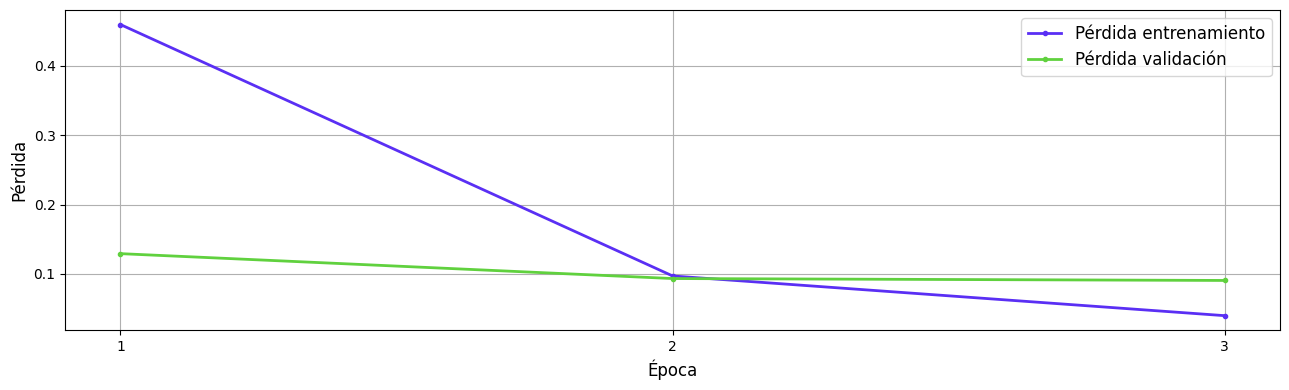

In [26]:
import matplotlib.pyplot as plt

def visualization_history(resultsFit):
    # Creamos la figura
    fig, axes = plt.subplots(1, 1, figsize=(13, 4))
    epocas = range(1, len(resultsFit["loss"]) + 1)

    # Pérdida de entrenamiento
    axes.plot(
        epocas, resultsFit["loss"],
        "#5a2ff4", linestyle="-", marker=".",
        label="Pérdida entrenamiento", lw=2
    )

    # Pérdida de validación
    axes.plot(
        epocas, resultsFit["val_loss"],
        "#60d13e", linestyle="-", marker=".",
        label="Pérdida validación", lw=2
    )

    # Configuración de los ejes
    axes.set_xlabel("Época", fontsize=12)
    axes.set_ylabel("Pérdida", fontsize=12)
    axes.set_xticks(list(epocas))
    axes.grid()
    axes.legend(fontsize=12, loc="upper right")

    plt.tight_layout()
    plt.show()

visualization_history(history)

# 5. Evaluación del modelo

Con los pesos de la mejor época, evaluamos los artículos del conjunto de prueba. Aplicamos softmax para obtener las probabilidades de las cinco categorías y calculamos precision, recall y F1-score para cada una.

In [27]:
from sklearn.metrics import classification_report

y_true = []
y_pred = []
y_prob = []

model.eval()

with torch.no_grad():
    for input_ids, attention_mask, labels in test_loader:
        outputs = model(
            input_ids=input_ids.to(device),
            attention_mask=attention_mask.to(device)
        )

        # Probabilidad de cada categoría y predicción final
        probabilities = torch.softmax(outputs.logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        # Conservamos resultados para las métricas y el análisis de errores
        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
        y_prob.extend(probabilities.cpu().tolist())

# Mantenemos el orden de categorías definido en label2id
ids_clases = list(range(len(label2id)))
nombres_clases = [id2label[i] for i in ids_clases]

print(classification_report(
    y_true,
    y_pred,
    labels=ids_clases,
    target_names=nombres_clases,
    digits=4,
    zero_division=0
))

               precision    recall  f1-score   support

     business     0.9867    0.9737    0.9801        76
entertainment     1.0000    1.0000    1.0000        55
     politics     0.9672    0.9672    0.9672        61
        sport     1.0000    1.0000    1.0000        76
         tech     0.9811    1.0000    0.9905        52

     accuracy                         0.9875       320
    macro avg     0.9870    0.9882    0.9876       320
 weighted avg     0.9875    0.9875    0.9875       320



## 5.1. Matriz de confusión

La siguiente matriz nos permite ver qué categorías se confundieron. Las filas corresponden a la categoría real y las columnas a la predicción del modelo.

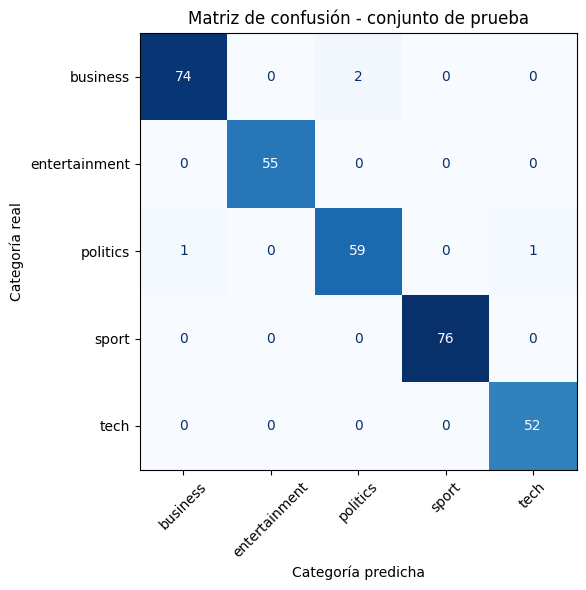

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Filas: categorías reales; columnas: categorías predichas
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=ids_clases
)

fig, ax = plt.subplots(figsize=(8, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nombres_clases
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("Matriz de confusión - conjunto de prueba")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")

plt.tight_layout()
plt.show()

## 5.2. Revisión de los artículos mal clasificados

Por último, revisamos los artículos en los que la predicción no coincide con la categoría del CSV. Mostramos el inicio del texto y la probabilidad asignada para entender mejor las confusiones que vimos en la matriz.

In [29]:
# Organizamos los resultados en el mismo orden del conjunto de prueba
resultados_test = pd.DataFrame({
    "texto": noticias_test["text"].tolist(),
    "real": [id2label[i] for i in y_true],
    "prediccion": [id2label[i] for i in y_pred],
    "probabilidad_predicha": np.array(y_prob).max(axis=1)
})

# Seleccionamos únicamente los artículos mal clasificados
errores = resultados_test[
    resultados_test["real"] != resultados_test["prediccion"]
]

print(f"Artículos mal clasificados: {len(errores)}")

# Mostramos el inicio de cada artículo para interpretar los errores
for indice, fila in errores.iterrows():
    print(f"\nArtículo {indice}")
    print(f"Categoría real: {fila['real']}")
    print(f"Predicción: {fila['prediccion']}")
    print(f"Probabilidad asignada: {fila['probabilidad_predicha']:.4f}")
    print(f"Texto:\n{fila['texto'][:1000]}")

Artículos mal clasificados: 4

Artículo 23
Categoría real: business
Predicción: politics
Probabilidad asignada: 0.9948
Texto:
Golden rule 'intact' says ex-aide

Chancellor Gordon Brown will meet his golden economic rule "with a margin to spare", according to his former chief economic adviser.

Formerly one of Mr Brown's closest Treasury aides, Ed Balls hinted at a Budget giveaway on 16 March. He said he hoped more would be done to build on current tax credit rules. Any rate rise ahead of an expected May election would not affect the Labour Party's chances of winning, he added. Last July, Mr Balls won the right to step down from his Treasury position and run for parliament, defending the Labour stronghold of Normanton in West Yorkshire.

Mr Balls rejected the allegation that Mr Brown had been sidelined in the election campaign, saying he was playing a "different" role to the one he played in the last two elections. He rejected speculation that Mr Brown was considering becoming Foreign S